# Task 1 - HAB prediction: preprocessing and model comparison

This notebook prepares the data and compares classifiers for predicting HAB events:

1. Split the data chronologically, 80% for training and 20% for testing.
2. Add the SST and UI of each cluster's previous sample, and how much they changed since then.
3. Fill the missing `CHL` and `CHL_uncertainty` values with the train medians.
4. Replace `CHL` with `log10(CHL)`, because it has a long right tail.
5. Z-score the continuous features with the train means and standard deviations.
6. One-hot encode `Season` and `spatial_cluster`.
7. Handle the class imbalance with balanced class weights instead of resampling.

Classifiers are compared with chronological 5-fold cross-validation on the train set, using the AUC on complete rows (rows with
a real `CHL` value), because the teaching team grades on complete rows only. Every value learned from data (medians, means,
standard deviations, class weights and the models) is refitted inside each fold, on the training blocks only.

In [1]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import ExtraTreesClassifier, HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC

DATA_PATH = Path("classification_task1_train.csv")
TARGET = "HAB"
IMPUTE_COLUMNS = ["CHL", "CHL_uncertainty"]
LOG_COLUMN = "CHL"
LAG_COLUMNS = ["prev_SST", "dSST", "prev_UI", "dUI"]
MAX_LAG_DAYS = 45
SCALE_COLUMNS = ["CHL", "CHL_uncertainty", "SST", "UI", "YDOY"] + LAG_COLUMNS
SEASON_ORDER = ["Winter", "Spring", "Summer", "Fall"]
CLUSTERS = [0, 1, 2, 3, 4, 5]
TRAIN_SHARE = 0.8
CV_FOLDS = 5
CV_SEEDS = range(5)

TRAIN_COLOR = "#2a78d6"
VALIDATION_COLOR = "#e8833a"
TEST_COLOR = "#9a9893"
GRID_COLOR = "#e4e3df"

## 1. Load the data

In [2]:
df = pd.read_csv(DATA_PATH, encoding="utf-8-sig", parse_dates=["Date"])
df = df.sort_values("Date", kind="stable").reset_index(drop=True)

print(f"{df.shape[0]} rows, {df['Date'].min():%Y-%m-%d} to {df['Date'].max():%Y-%m-%d}, "
      f"HAB rate {df[TARGET].mean():.1%}")
df.isna().sum().to_frame("missing values").T

1063 rows, 2013-02-19 to 2020-12-29, HAB rate 13.0%


,Date,Day,Month,Year,Season,CHL,CHL_uncertainty,SST,UI,YDOY,spatial_cluster,HAB
missing values,0,0,0,0,0,500,500,0,0,0,0,0


## 2. Chronological train/test split

The earliest 80% of the rows form the train set and the rest the test set, because the model will be graded on later years
(2021-2023). The cut falls between two dates, so no date is in both sets.

In [3]:
cutoff_date = df["Date"].iloc[int(len(df) * TRAIN_SHARE)]
train = df[df["Date"] < cutoff_date]
test = df[df["Date"] >= cutoff_date]
assert train["Date"].max() < test["Date"].min(), "Train and test overlap in time"


def split_summary(data):
    """Return the size, date range, HAB rate and share of complete rows of a split."""
    return {
        "rows": len(data),
        "first date": f"{data['Date'].min():%Y-%m-%d}",
        "last date": f"{data['Date'].max():%Y-%m-%d}",
        "positives": data[TARGET].sum(),
        "HAB rate (%)": round(data[TARGET].mean() * 100, 1),
        "complete rows": data["CHL"].notna().sum(),
    }


pd.DataFrame({"Train": split_summary(train), "Test": split_summary(test)}).T

,rows,first date,last date,positives,HAB rate (%),complete rows
Train,850,2013-02-19,2019-08-19,98,11.5,452
Test,213,2019-08-21,2020-12-29,40,18.8,111


## 3. Previous-sample features

Each cluster is sampled about once a week. For every row, the previous row of the same cluster gives four features:

- `prev_SST` and `prev_UI`: the SST and upwelling index of that previous sample;
- `dSST = SST - prev_SST` and `dUI = UI - prev_UI`: how much they changed since then.

The previous sample is only used if it is at most 45 days old. Otherwise, as for a cluster's first row, `prev` is the current
value and the change is 0. Only the features of earlier rows are used, never their labels, which the test file doesn't have.
The manual asks `train.py` to build lagged variables and forbids future rows. Each cluster has at most one row per date, so the
previous row always has an earlier date.

The features are computed once on all rows sorted by date, so the first test rows use the last train rows. The check computes
them on the train set alone and confirms that nothing changes, so no row's features depend on a later row.

In [4]:
def previous_sample_features(data):
    """Return prev_SST, dSST, prev_UI and dUI from the same cluster's previous row, if at most MAX_LAG_DAYS old."""
    assert data["Date"].is_monotonic_increasing, "The data must be sorted by date"
    assert not data.duplicated(["Date", "spatial_cluster"]).any(), "A cluster has two rows on one date"
    by_cluster = data.groupby("spatial_cluster", sort=False)
    recent = (data["Date"] - by_cluster["Date"].shift()).dt.days <= MAX_LAG_DAYS
    lags = pd.DataFrame(index=data.index)
    for column in ["SST", "UI"]:
        lags[f"prev_{column}"] = by_cluster[column].shift().where(recent).fillna(data[column])
        lags[f"d{column}"] = data[column] - lags[f"prev_{column}"]
    return lags[LAG_COLUMNS]


df[LAG_COLUMNS] = previous_sample_features(df)
train = df[df["Date"] < cutoff_date]
test = df[df["Date"] >= cutoff_date]
assert previous_sample_features(train).equals(train[LAG_COLUMNS]), "Train lags depend on later rows"

gap = df.groupby("spatial_cluster")["Date"].diff().dt.days
print(f"Rows with a previous sample of the same cluster at most {MAX_LAG_DAYS} days old: {(gap <= MAX_LAG_DAYS).mean():.0%} "
      f"(median gap {gap.median():.0f} days)")
train[LAG_COLUMNS].describe().round(2)

Rows with a previous sample of the same cluster at most 45 days old: 97% (median gap 7 days)


,prev_SST,dSST,prev_UI,dUI
count,850.00,850.00,850.00,850.00
mean,14.63,0.03,0.07,-0.00
std,1.72,1.87,0.38,0.47
min,11.21,-6.65,-1.98,-1.96
25%,13.35,-0.78,-0.03,-0.18
50%,14.40,0.00,0.04,0.00
75%,15.65,0.93,0.19,0.19
max,20.74,6.98,2.00,2.47


## 4. Preprocessing

`fit_preprocessing()` learns the values the preprocessing needs from one set of rows, and `apply_preprocessing()` applies
them to any rows, in this order:

1. **Median imputation:** missing `CHL` and `CHL_uncertainty` get the median of the fitting rows. The manual doesn't allow
   library imputers, so this uses plain pandas.
2. **Log transform:** `CHL` becomes `log10(CHL)`, which cuts its skewness from about 5.4 to 1.0.
3. **Z-score:** each continuous feature (the five measurements and the four previous-sample features) becomes
   `(value - mean) / std`, with the mean and standard deviation of the fitting rows.

`Season` and `spatial_cluster` are categories and are one-hot encoded in section 5. `Date`, `Day`, `Month` and `Year` aren't
used, because the manual describes them as redundant.

In [5]:
def log_chl(data):
    """Return a copy of the data with LOG_COLUMN replaced by its log10."""
    assert (data[LOG_COLUMN] > 0).all(), "log10 needs positive values"
    logged = data.copy()
    logged[LOG_COLUMN] = np.log10(data[LOG_COLUMN])
    return logged


def fit_preprocessing(data):
    """Return the imputation medians and the scaling means and standard deviations learned from the data."""
    medians = data[IMPUTE_COLUMNS].median()
    logged = log_chl(data.fillna(medians))
    stds = logged[SCALE_COLUMNS].std(ddof=0)
    assert (stds > 0).all(), "A feature is constant"
    return medians, logged[SCALE_COLUMNS].mean(), stds


def apply_preprocessing(data, medians, means, stds):
    """Impute, log-transform CHL and z-score the data with previously learned values."""
    prepared = log_chl(data.fillna(medians))
    prepared[SCALE_COLUMNS] = (prepared[SCALE_COLUMNS] - means) / stds
    return prepared


train_medians, train_means, train_stds = fit_preprocessing(train)
train_scaled = apply_preprocessing(train, train_medians, train_means, train_stds)
test_scaled = apply_preprocessing(test, train_medians, train_means, train_stds)

for name, original, scaled in [("Train", train, train_scaled), ("Test", test, test_scaled)]:
    assert scaled[SCALE_COLUMNS].notna().all().all(), f"{name}: missing values remain"
    assert len(scaled) == len(original), f"{name}: row count changed"
    observed = original["CHL"].notna()
    restored = 10 ** (scaled.loc[observed, "CHL"] * train_stds["CHL"] + train_means["CHL"])
    assert ((restored - original.loc[observed, "CHL"]).abs() < 1e-9).all(), f"{name}: observed CHL changed"
assert (train_scaled[SCALE_COLUMNS].mean().abs() < 1e-9).all(), "Scaled train means are not 0"
assert ((train_scaled[SCALE_COLUMNS].std(ddof=0) - 1).abs() < 1e-9).all(), "Scaled train stds are not 1"
print("All preprocessing checks passed")

pd.DataFrame({
    "median (fills missing)": train_medians,
    "mean (after log)": train_means,
    "std (after log)": train_stds,
}).reindex(SCALE_COLUMNS).round(3)

All preprocessing checks passed


,median (fills missing),mean (after log),std (after log)
CHL,2.892,0.501,0.303
CHL_uncertainty,32.455,35.816,15.899
SST,NaN,14.657,1.717
UI,NaN,0.064,0.381
YDOY,NaN,-0.060,0.693
prev_SST,NaN,14.628,1.714
dSST,NaN,0.029,1.868
prev_UI,NaN,0.065,0.380
dUI,NaN,-0.001,0.469


## 5. Feature matrix and class weights

The models use the nine scaled features plus one-hot columns for `Season` and `spatial_cluster`, built from the full list of
categories, so every matrix has the same 19 columns in the same order.

Only 11.5% of the train rows are HAB events. Instead of resampling, every classifier that supports it uses
`class_weight="balanced"`, which weights each row by `rows / (2 x rows of its class)`. A HAB row then counts about 7.7 times as
much as a non-HAB row, and both classes carry the same total weight. This scored as well as SMOTE and random oversampling in
the earlier experiments, without adding synthetic or copied rows. The weights inflate the predicted probabilities, but they
don't change the ranking of the rows, so they don't affect the AUC.

In [6]:
def feature_matrix(data):
    """Return the model inputs: scaled features, then one-hot Season and spatial_cluster columns."""
    features = data[SCALE_COLUMNS].copy()
    for season in SEASON_ORDER:
        features[f"Season_{season}"] = (data["Season"] == season).astype(float)
    for cluster in CLUSTERS:
        features[f"cluster_{cluster}"] = (data["spatial_cluster"] == cluster).astype(float)
    return features


X_train, y_train = feature_matrix(train_scaled), train_scaled[TARGET]
X_test, y_test = feature_matrix(test_scaled), test_scaled[TARGET]
assert list(X_train.columns) == list(X_test.columns), "Train and test columns differ"
assert (X_train.filter(like="Season_").sum(axis=1) == 1).all() and (X_train.filter(like="cluster_").sum(axis=1) == 1).all()

counts = y_train.value_counts().sort_index()
weights = len(y_train) / (2 * counts)
print(f"{X_train.shape[1]} features: {list(X_train.columns)}")
pd.DataFrame({"train rows": counts, "balanced weight": weights.round(3), "total weight": (counts * weights).round(1)},
             index=pd.Index([0, 1], name=TARGET))

19 features: ['CHL', 'CHL_uncertainty', 'SST', 'UI', 'YDOY', 'prev_SST', 'dSST', 'prev_UI', 'dUI', 'Season_Winter', 'Season_Spring', 'Season_Summer', 'Season_Fall', 'cluster_0', 'cluster_1', 'cluster_2', 'cluster_3', 'cluster_4', 'cluster_5']


,train rows,balanced weight,total weight
HAB,,,
0,752,0.565,425.0
1,98,4.337,425.0


## 6. Chronological 5-fold cross-validation

The train set is cut into 5 consecutive time blocks of 170 rows, with the cuts between dates. Each block is the validation
fold once, and the model is fitted on the other 4. Training also uses blocks later than the validation block, because
training only on earlier blocks would leave a validation block (February to November 2017) with no HAB events. The test set
is never used here.

The plot shows, for each fold, which part of the timeline is used for training, for validation and for testing. The last row
is the final check, where the model is fitted on the whole train set and scored on the test set.

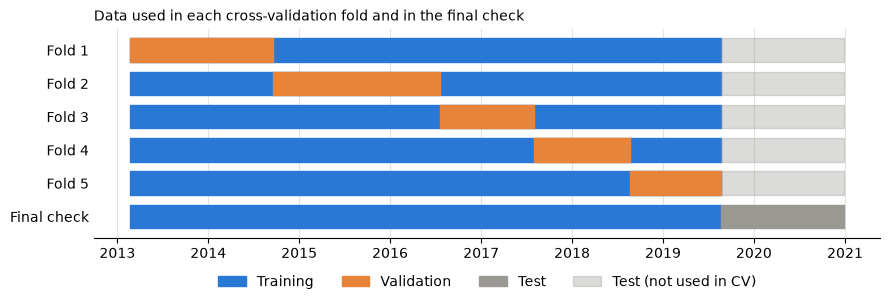

,validation from,validation to,rows,positives,complete rows,complete positives
fold,,,,,,
1,2013-02-19,2014-09-09,170,10,80,8
2,2014-09-16,2016-07-19,170,38,71,17
3,2016-07-20,2017-07-26,170,8,102,7
4,2017-07-31,2018-08-20,170,19,100,10
5,2018-08-21,2019-08-19,170,23,99,13


In [7]:
cut_dates = pd.to_datetime([train["Date"].iloc[int(len(train) * i / CV_FOLDS)] for i in range(1, CV_FOLDS)])
fold_of_row = np.searchsorted(cut_dates.to_numpy(), train["Date"].to_numpy(), side="right")

fold_table = pd.DataFrame([{
    "fold": fold + 1,
    "validation from": f"{train['Date'][fold_of_row == fold].min():%Y-%m-%d}",
    "validation to": f"{train['Date'][fold_of_row == fold].max():%Y-%m-%d}",
    "rows": (fold_of_row == fold).sum(),
    "positives": train[TARGET][fold_of_row == fold].sum(),
    "complete rows": train["CHL"][fold_of_row == fold].notna().sum(),
    "complete positives": train[TARGET][(fold_of_row == fold) & train["CHL"].notna().to_numpy()].sum(),
} for fold in range(CV_FOLDS)]).set_index("fold")

boundaries = mdates.date2num([train["Date"].min(), *cut_dates, cutoff_date])
test_span = (mdates.date2num(cutoff_date), mdates.date2num(test["Date"].max()) - mdates.date2num(cutoff_date))
fig, ax = plt.subplots(figsize=(9, 3.2))
for fold in range(CV_FOLDS):
    row = CV_FOLDS - fold
    ax.broken_barh([(boundaries[0], boundaries[-1] - boundaries[0])], (row - 0.35, 0.7), color=TRAIN_COLOR)
    ax.broken_barh([(boundaries[fold], boundaries[fold + 1] - boundaries[fold])], (row - 0.35, 0.7), color=VALIDATION_COLOR)
    ax.broken_barh([test_span], (row - 0.35, 0.7), color=TEST_COLOR, alpha=0.35)
ax.broken_barh([(boundaries[0], boundaries[-1] - boundaries[0])], (-0.35, 0.7), color=TRAIN_COLOR)
ax.broken_barh([test_span], (-0.35, 0.7), color=TEST_COLOR)
ax.set_yticks(range(CV_FOLDS + 1), ["Final check", *[f"Fold {fold + 1}" for fold in reversed(range(CV_FOLDS))]])
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.xaxis.grid(True, color=GRID_COLOR)
ax.set_axisbelow(True)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0)
handles = [plt.Rectangle((0, 0), 1, 1, color=color, alpha=alpha) for color, alpha in
           [(TRAIN_COLOR, 1), (VALIDATION_COLOR, 1), (TEST_COLOR, 1), (TEST_COLOR, 0.35)]]
ax.legend(handles, ["Training", "Validation", "Test", "Test (not used in CV)"], ncol=4, frameon=False,
          loc="upper center", bbox_to_anchor=(0.5, -0.12))
ax.set_title("Data used in each cross-validation fold and in the final check", loc="left", fontsize=10)
fig.tight_layout()
plt.show()

fold_table

Every fold is prepared the same way: the preprocessing is fitted on the 4 training blocks and applied to both parts. AUC is
computed on the validation fold's complete rows, which is what the grading uses, and also on all its rows, including the ones
whose `CHL` was imputed.

In [8]:
fold_data = []
for fold in range(CV_FOLDS):
    fit_part, val_part = train[fold_of_row != fold], train[fold_of_row == fold]
    learned = fit_preprocessing(fit_part)
    fold_data.append({
        "fit_part": fit_part,
        "val_part": val_part,
        "X_fit": feature_matrix(apply_preprocessing(fit_part, *learned)),
        "y_fit": fit_part[TARGET].to_numpy(),
        "X_val": feature_matrix(apply_preprocessing(val_part, *learned)),
        "y_val": val_part[TARGET].to_numpy(),
        "complete": val_part["CHL"].notna().to_numpy(),
    })


def fold_aucs(data, scores):
    """Return the AUC of one fold's validation scores on all rows and on complete rows."""
    return {
        "AUC (all rows)": roc_auc_score(data["y_val"], scores),
        "AUC (complete rows)": roc_auc_score(data["y_val"][data["complete"]], scores[data["complete"]]),
    }

## 7. Baseline: HAB rate per season and cluster

The baseline is a look-up table: it predicts, for each row, the share of training rows with `HAB = 1` that have the same
`Season` and `spatial_cluster`. A pair with no training rows gets the overall training rate. It needs no preprocessing, so it
is fitted on the raw training rows. Any classifier should beat it to be worth using.

The table shows the look-up table learned from the whole train set, and the cell scores the baseline on the 5 folds.

In [9]:
def fit_rate_baseline(data):
    """Return the HAB rate of each (Season, spatial_cluster) pair and the overall HAB rate."""
    return {"rates": data.groupby(["Season", "spatial_cluster"])[TARGET].mean(), "overall": data[TARGET].mean()}


def predict_rate_baseline(baseline, data):
    """Return the HAB rate of each row's pair, or the overall rate for pairs unseen during fitting."""
    pairs = pd.MultiIndex.from_frame(data[["Season", "spatial_cluster"]])
    return baseline["rates"].reindex(pairs).fillna(baseline["overall"]).to_numpy()


cv_rows = []
for fold, data in enumerate(fold_data):
    scores = predict_rate_baseline(fit_rate_baseline(data["fit_part"]), data["val_part"])
    cv_rows.append({"model": "Baseline (season x cluster rate)", "fold": fold + 1, **fold_aucs(data, scores)})

baseline_table = fit_rate_baseline(train)["rates"].unstack("spatial_cluster").reindex(SEASON_ORDER)
baseline_table = (baseline_table * 100).round(1)
baseline_table.columns = [f"cluster {cluster}" for cluster in baseline_table.columns]
print("HAB rate (%) per season and cluster in the train set; empty cells have no rows and get the overall rate "
      f"({train[TARGET].mean():.1%})")
baseline_table

HAB rate (%) per season and cluster in the train set; empty cells have no rows and get the overall rate (11.5%)


,cluster 0,cluster 1,cluster 2,cluster 3,cluster 4,cluster 5
Season,,,,,,
Winter,1.0,0.0,NaN,NaN,12.8,0.0
Spring,3.8,NaN,17.6,0.0,16.0,4.7
Summer,17.9,NaN,53.3,NaN,32.4,23.8
Fall,1.2,0.0,21.4,NaN,11.5,0.0


## 8. Classifier comparison

Every classifier is trained on the same 5 folds, with the settings that scored best in the earlier experiments:

| Classifier | Settings | Imbalance |
|---|---|---|
| Logistic regression | L2 penalty, `C = 1`, fitted with scikit-learn's Newton solver (`newton-cholesky`) | balanced class weights |
| kNN | 101 neighbours, uniform weights, Euclidean distance | none: kNN has no class weights, and the AUC only needs the ranking |
| SVM | RBF kernel, `C = 1`, `gamma = 0.01`, scored with its decision value | balanced class weights |
| Gradient boosting | `HistGradientBoostingClassifier`: depth 2, 50 trees, at least 60 rows per leaf, learning rate 0.05, L2 penalty 1 | balanced class weights |
| Random forest | 300 trees, depth 4, at least 30 rows per leaf | balanced class weights |
| MLP | one hidden layer of 2 ReLU neurons, L2 penalty `alpha = 1`, Adam | none: `MLPClassifier` has no class weights in scikit-learn 1.6 |
| Logistic regression + extra trees | the mean of the logistic regression probability and the probability of extra trees with 200 trees and at least 2 rows per leaf | balanced class weights |

Gradient boosting uses scikit-learn's `HistGradientBoostingClassifier` instead of XGBoost, which isn't in the manual's list of
allowed dependencies. Random forest, extra trees and the MLP depend on their seed, so they are trained with 5 seeds per fold
and their fold score is the mean.

In [10]:
def logistic_regression(seed):
    return LogisticRegression(C=1, solver="newton-cholesky", max_iter=100, class_weight="balanced")


def knn(seed):
    return KNeighborsClassifier(n_neighbors=101)


def svm(seed):
    return SVC(kernel="rbf", C=1, gamma=0.01, class_weight="balanced")


def gradient_boosting(seed):
    return HistGradientBoostingClassifier(max_depth=2, max_iter=50, min_samples_leaf=60, learning_rate=0.05,
                                          l2_regularization=1.0, class_weight="balanced", random_state=seed)


def random_forest(seed):
    return RandomForestClassifier(n_estimators=300, max_depth=4, min_samples_leaf=30, class_weight="balanced",
                                  n_jobs=-1, random_state=seed)


def extra_trees(seed):
    return ExtraTreesClassifier(n_estimators=200, min_samples_leaf=2, class_weight="balanced", n_jobs=-1,
                                random_state=seed)


def mlp(seed):
    return MLPClassifier(hidden_layer_sizes=(2,), activation="relu", solver="adam", alpha=1.0, max_iter=2000,
                         random_state=seed)


# name: (builder, seeds); deterministic models are fitted once per fold.
CLASSIFIERS = {
    "Logistic regression": (logistic_regression, [0]),
    "kNN": (knn, [0]),
    "SVM": (svm, [0]),
    "Gradient boosting": (gradient_boosting, [0]),
    "Random forest": (random_forest, CV_SEEDS),
    "MLP": (mlp, CV_SEEDS),
    "Extra trees": (extra_trees, CV_SEEDS),
}


def positive_scores(model, X):
    """Return a score per row that ranks how likely HAB = 1 is: the probability, or the SVM's decision value."""
    if isinstance(model, SVC):
        return model.decision_function(X)
    return model.predict_proba(X)[:, 1]


def classifier_scores(name, data):
    """Return one classifier's validation scores on a fold, averaged over its seeds."""
    build, seeds = CLASSIFIERS[name]
    return np.mean([positive_scores(build(seed).fit(data["X_fit"], data["y_fit"]), data["X_val"]) for seed in seeds],
                   axis=0)


for fold, data in enumerate(fold_data):
    scores = {name: classifier_scores(name, data) for name in CLASSIFIERS}
    scores["Logistic regression + extra trees"] = (scores["Logistic regression"] + scores.pop("Extra trees")) / 2
    for name, model_scores in scores.items():
        cv_rows.append({"model": name, "fold": fold + 1, **fold_aucs(data, model_scores)})

cv_results = pd.DataFrame(cv_rows)
cv_results.pivot(index="fold", columns="model", values="AUC (complete rows)").round(3)

C:\Users\barba\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\barba\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\barba\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\b

model,Baseline (season x cluster rate),Gradient boosting,Logistic regression,Logistic regression + extra trees,MLP,Random forest,SVM,kNN
fold,,,,,,,,
1,0.530,0.580,0.686,0.675,0.627,0.533,0.556,0.418
2,0.767,0.828,0.805,0.804,0.791,0.874,0.861,0.812
3,0.840,0.843,0.869,0.866,0.889,0.871,0.886,0.855
4,0.832,0.839,0.871,0.857,0.868,0.866,0.890,0.877
5,0.826,0.790,0.828,0.868,0.803,0.805,0.818,0.754


### Cross-validation results

Mean AUC over the 5 folds ± its standard deviation across folds, sorted by the AUC on complete rows.

In [11]:
summary = cv_results.groupby("model")[["AUC (complete rows)", "AUC (all rows)"]].agg(["mean", "std"])
summary = summary.sort_values(("AUC (complete rows)", "mean"), ascending=False)
results_table = pd.DataFrame({
    column: summary[(column, "mean")].map("{:.3f}".format) + " ± " + summary[(column, "std")].map("{:.3f}".format)
    for column in ["AUC (complete rows)", "AUC (all rows)"]
})
results_table.index.name = "classifier"
results_table

,AUC (complete rows),AUC (all rows)
classifier,,
Logistic regression + extra trees,0.814 ± 0.082,0.798 ± 0.086
Logistic regression,0.812 ± 0.076,0.797 ± 0.080
SVM,0.802 ± 0.141,0.791 ± 0.120
MLP,0.795 ± 0.103,0.787 ± 0.098
Random forest,0.790 ± 0.146,0.765 ± 0.112
Gradient boosting,0.776 ± 0.112,0.746 ± 0.091
Baseline (season x cluster rate),0.759 ± 0.132,0.759 ± 0.121
kNN,0.743 ± 0.188,0.727 ± 0.138


## 9. Findings

- **Logistic regression + extra trees and logistic regression alone are tied at the top:** 0.814 ± 0.082 and 0.812 ± 0.076 on
  complete rows. Logistic regression alone is higher in 4 of the 5 folds. The ensemble's mean is higher only because of fold 5
  (0.868 against 0.828).
- **The previous-sample features help most classifiers.** Compared with the same models without them, logistic regression goes
  from 0.800 to 0.812, SVM from 0.797 to 0.802, MLP from 0.788 to 0.795, random forest from 0.784 to 0.790, and the ensemble from
  0.811 to 0.814. They don't help gradient boosting (0.781 to 0.776) or kNN (0.763 to 0.743), which falls below the baseline.
- **SVM, MLP, random forest and gradient boosting** score 0.776 to 0.802, below the top two but within the noise of the folds
  (std 0.10 to 0.15).
- **Fold 1 (2013-2014) is the hardest fold for every model** (0.42 to 0.69), and most of the spread across folds comes from it.
- **The baseline is strong:** the season and cluster alone give 0.759, so the other features add about 0.05 AUC.

**Choosing between the top two:** cross-validation can't separate them. Logistic regression alone is chosen: it's the
simpler model (one model, no seeds), and it was higher in 4 of the 5 folds.

## 10. Final model and test check

The chosen model is logistic regression on the 19 features, with `C = 1`, balanced class weights and the Newton solver. It is refitted on the
whole train set (2013 to August 2019), with the preprocessing values learned from the whole train set in section 4. Its
intercept is then corrected so that its outputs are probabilities (see below). It is then scored once on the test set
(August 2019 to December 2020), which played no part in any choice. The baseline look-up table is
refitted and scored the same way for comparison.

### Training and validation loss per iteration

The logistic regression is fitted with scikit-learn's Newton solver (`newton-cholesky`). Each iteration uses the exact first
and second derivatives of the loss. With only 20 parameters (19 coefficients and the intercept) the second derivatives are
cheap to compute, so the solver reaches the minimum in a few iterations. The loss is convex, so any solver finds the same
minimum, and the solver doesn't change the predictions.

scikit-learn doesn't keep a loss history, but the solver is deterministic: a fit stopped after `k` iterations (`max_iter=k`)
is exactly the real solver after its `k`-th iteration. This cell refits with `max_iter` from 1 to 8 and computes the loss of
each fit. Iteration 0 is the starting point, with all weights at 0.

- **Left:** the loss the solver minimizes on the whole train set, the class-weighted cross-entropy plus the L2 penalty
  `||beta||^2 / (2 C n)` (scikit-learn's loss divided by `C n`).
- **Right:** the same refits inside each of the 5 cross-validation folds, with the class-weighted cross-entropy on the
  training blocks and on the validation block's complete rows. If the model overfitted, the validation loss would turn up
  while the training loss keeps falling.

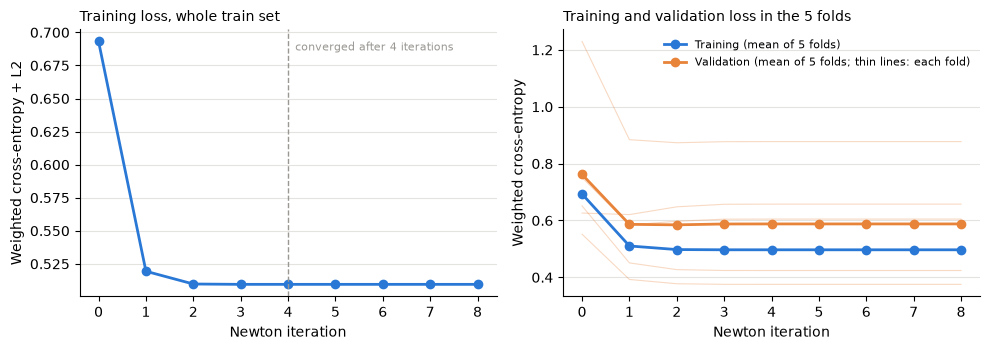

whole train set 5 folds (mean)           
                objective          train validation
iteration                                          
0                  0.6931         0.6931     0.7619
1                  0.5194         0.5104     0.5865
2                  0.5098         0.4977     0.5847
3                  0.5095         0.4969     0.5877
4                  0.5095         0.4969     0.5879
5                  0.5095         0.4969     0.5879
6                  0.5095         0.4969     0.5879
7                  0.5095         0.4969     0.5879
8                  0.5095         0.4969     0.5879

In [12]:
import warnings

from sklearn.exceptions import ConvergenceWarning

SOLVER_ITERATIONS = 8


def weighted_cross_entropy(X, y, row_weights, coef, intercept):
    """Return the mean class-weighted cross-entropy of a logistic model."""
    logits = X @ coef + intercept
    return np.mean(row_weights * (np.logaddexp(0, logits) - y * logits))


def solver_loss_path(X_fit, y_fit, X_val=None, y_val=None):
    """Return the loss after each Newton iteration of the logistic regression, from 0 to SOLVER_ITERATIONS.

    scikit-learn keeps no loss history, but the solver is deterministic, so a fit stopped after k iterations
    (max_iter=k) is exactly the real solver after its k-th iteration. Iteration 0 is the starting point, all weights at 0.
    The validation loss uses the training rows' class weights.
    """
    X_fit, X_val = np.asarray(X_fit), None if X_val is None else np.asarray(X_val)
    counts = np.bincount(y_fit, minlength=2)
    class_weights = len(y_fit) / (2 * counts)
    path = []
    for iterations in range(SOLVER_ITERATIONS + 1):
        if iterations == 0:
            coef, intercept = np.zeros(X_fit.shape[1]), 0.0
        else:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore", ConvergenceWarning)
                model = LogisticRegression(C=1, solver="newton-cholesky", max_iter=iterations,
                                           class_weight="balanced").fit(X_fit, y_fit)
            coef, intercept = model.coef_[0], model.intercept_[0]
        train_ce = weighted_cross_entropy(X_fit, y_fit, class_weights[y_fit], coef, intercept)
        record = {"iteration": iterations, "objective": train_ce + coef @ coef / (2 * len(y_fit)), "train": train_ce}
        if X_val is not None:
            record["validation"] = weighted_cross_entropy(X_val, y_val, class_weights[y_val], coef, intercept)
        path.append(record)
    return pd.DataFrame(path).set_index("iteration")


final_path = solver_loss_path(X_train, y_train.to_numpy())
fold_paths = pd.concat({
    fold + 1: solver_loss_path(data["X_fit"], data["y_fit"], data["X_val"].to_numpy()[data["complete"]],
                               data["y_val"][data["complete"]])
    for fold, data in enumerate(fold_data)
}, names=["fold"])
mean_path = fold_paths.groupby("iteration")[["train", "validation"]].mean()
converged = logistic_regression(seed=0).fit(X_train, y_train).n_iter_[0]

fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.6))
left.plot(final_path.index, final_path["objective"], color=TRAIN_COLOR, linewidth=2, marker="o")
left.axvline(converged, color=TEST_COLOR, linestyle="--", linewidth=1)
left.text(converged + 0.15, final_path["objective"].max(), f"converged after {converged} iterations", color=TEST_COLOR,
          fontsize=8, va="top")
left.set_ylabel("Weighted cross-entropy + L2")
left.set_title("Training loss, whole train set", loc="left", fontsize=10)
for fold, path in fold_paths.groupby("fold"):
    right.plot(path.index.get_level_values("iteration"), path["validation"], color=VALIDATION_COLOR, linewidth=0.8,
               alpha=0.3)
right.plot(mean_path.index, mean_path["train"], color=TRAIN_COLOR, linewidth=2, marker="o",
           label="Training (mean of 5 folds)")
right.plot(mean_path.index, mean_path["validation"], color=VALIDATION_COLOR, linewidth=2, marker="o",
           label="Validation (mean of 5 folds; thin lines: each fold)")
right.set_ylabel("Weighted cross-entropy")
right.set_title("Training and validation loss in the 5 folds", loc="left", fontsize=10)
right.legend(frameon=False, fontsize=8)
for ax in (left, right):
    ax.set_xlabel("Newton iteration")
    ax.set_xticks(range(SOLVER_ITERATIONS + 1))
    ax.yaxis.grid(True, color=GRID_COLOR)
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

pd.concat({"whole train set": final_path[["objective"]], "5 folds (mean)": mean_path}, axis=1).round(4)

**No meaningful overfitting.** On the whole train set the solver converges in 4 iterations. The loss drops from 0.693 to 0.519
after the first iteration and stops changing after the third.

In the folds, the mean validation loss is lowest after iteration 2 (0.5847) and ends 0.003 higher at convergence (0.5879),
while the training loss falls by only 0.001 over the same iterations. That rise is tiny next to the spread between folds (the
thin lines end between about 0.37 and 0.88), so stopping early would change almost nothing. The L2 penalty already does the
regularizing.

The validation loss stays above the training loss (0.588 against 0.497), because each fold is scored on a period the model
hasn't seen. The highest thin line is fold 1 (2013-2014), the fold with the lowest AUC.

### From class-weighted score to probability

`predict` must return the probability of a HAB event. Balanced class weights make the model fit as if the two classes were
equally common, which multiplies the odds it predicts by `w_1 / w_0 = n_0 / n_1` (752 / 98, about 7.7 on the train set).
Its outputs are therefore far above the real HAB rate. Subtracting `log(w_1 / w_0)` from the intercept undoes this and brings
the outputs back to the train set's HAB rate.

The shift is the same for every row, so the ranking of the rows, and with it the AUC, is exactly unchanged. The cell checks
this and compares the mean output with the real HAB rate before and after the correction.

In [13]:
import copy


def correct_class_weight_bias(model, y):
    """Return a copy of a class-weighted logistic regression whose intercept is shifted by -log(w_1 / w_0).

    The weights are the balanced class weights of the training labels y. The copy outputs probabilities at the training
    rows' HAB rate instead of a 50/50 rate.
    """
    counts = np.bincount(y, minlength=2)
    class_weights = len(y) / (2 * counts)
    shift = np.log(class_weights[1] / class_weights[0])
    corrected = copy.deepcopy(model)
    corrected.intercept_ = model.intercept_ - shift
    return corrected, shift


weighted_model = logistic_regression(seed=0).fit(X_train, y_train)
final_model, intercept_shift = correct_class_weight_bias(weighted_model, y_train.to_numpy())
print(f"Intercept {weighted_model.intercept_[0]:.3f} - log({np.exp(intercept_shift):.2f}) = {final_model.intercept_[0]:.3f}")

correction_rows = {}
for name, X, y in [("train", X_train, y_train), ("test", X_test, y_test)]:
    weighted_scores = weighted_model.predict_proba(X)[:, 1]
    corrected_scores = final_model.predict_proba(X)[:, 1]
    assert roc_auc_score(y, weighted_scores) == roc_auc_score(y, corrected_scores), f"{name}: the correction changed the AUC"
    correction_rows[name] = {
        "real HAB rate": y.mean(),
        "mean output, class-weighted": weighted_scores.mean(),
        "mean output, corrected": corrected_scores.mean(),
        "AUC, class-weighted": roc_auc_score(y, weighted_scores),
        "AUC, corrected": roc_auc_score(y, corrected_scores),
    }
pd.DataFrame(correction_rows).T.round(3)

Intercept -0.669 - log(7.67) = -2.707


,real HAB rate,"mean output, class-weighted","mean output, corrected","AUC, class-weighted","AUC, corrected"
train,0.115,0.375,0.119,0.829,0.829
test,0.188,0.332,0.104,0.858,0.858


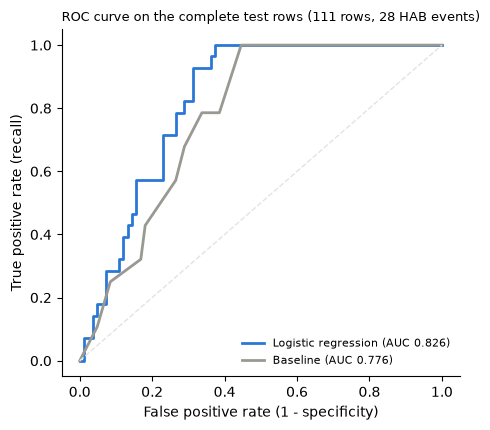

,CV AUC (complete rows),train AUC (all rows),test AUC (complete rows),test AUC (all rows)
Logistic regression,0.812,0.829,0.826,0.858
Baseline (season x cluster rate),0.759,0.793,0.776,0.825


In [14]:
from sklearn.metrics import roc_curve

test_scores = final_model.predict_proba(X_test)[:, 1]
complete_test = test["CHL"].notna().to_numpy()
final_baseline = fit_rate_baseline(train)
baseline_test_scores = predict_rate_baseline(final_baseline, test)


def final_scores(cv_name, train_scores, scores):
    """Return the CV, train and test AUCs of a model refitted on the whole train set."""
    return {
        "CV AUC (complete rows)": summary.loc[cv_name, ("AUC (complete rows)", "mean")],
        "train AUC (all rows)": roc_auc_score(y_train, train_scores),
        "test AUC (complete rows)": roc_auc_score(y_test[complete_test], scores[complete_test]),
        "test AUC (all rows)": roc_auc_score(y_test, scores),
    }


test_table = pd.DataFrame({
    "Logistic regression": final_scores("Logistic regression", final_model.predict_proba(X_train)[:, 1], test_scores),
    "Baseline (season x cluster rate)": final_scores("Baseline (season x cluster rate)",
                                                     predict_rate_baseline(final_baseline, train), baseline_test_scores),
}).T

fig, ax = plt.subplots(figsize=(4.8, 4.4))
for name, scores, color in [("Logistic regression", test_scores, TRAIN_COLOR),
                            ("Baseline", baseline_test_scores, TEST_COLOR)]:
    false_positive_rate, true_positive_rate, _ = roc_curve(y_test[complete_test], scores[complete_test])
    auc = roc_auc_score(y_test[complete_test], scores[complete_test])
    ax.plot(false_positive_rate, true_positive_rate, color=color, linewidth=2, label=f"{name} (AUC {auc:.3f})")
ax.plot([0, 1], [0, 1], color=GRID_COLOR, linestyle="--", linewidth=1)
ax.set_xlabel("False positive rate (1 - specificity)")
ax.set_ylabel("True positive rate (recall)")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="lower right", fontsize=8)
ax.set_title(f"ROC curve on the complete test rows ({complete_test.sum()} rows, {y_test[complete_test].sum()} HAB events)",
             loc="left", fontsize=9)
fig.tight_layout()
plt.show()

test_table.round(3)

## 11. Test results

- **The model holds up on the test set:** 0.826 AUC on the complete test rows (111 rows, 28 HAB events) and 0.858 on all test rows.
  The cross-validation estimate was 0.812, so the test score is in line with it, within the spread across folds.
- **It beats the baseline by about 0.05,** as in cross-validation: 0.826 against 0.776 on complete rows, and 0.858 against 0.825 on
  all rows.
- **It doesn't overfit:** the AUC on the train rows (0.829) is about the same as on the test rows.
- **On the ROC curve,** the model catches all 28 HAB events while flagging about 37% of the non-events, where the baseline needs
  about 45%.
- **The intercept correction works on the train set and leaves the AUC unchanged:** the mean output falls from 0.375 to 0.119,
  against a real HAB rate of 0.115. On the test set it gives 0.104, while HAB events made up 18.8% of the rows. The test period
  had more events than 2013-2019, and the model's probabilities assume the training rate.
- **With only 28 HAB events,** the test AUC is uncertain by a few hundredths, so it confirms the choice rather than measuring it
  precisely.

For the submission, the same pipeline should be refitted on all the released data (2013-2020) before saving `model.pkl`.